# D47 · 프로젝트 ③ 성능 개선 · 리팩터링: 느린 자동 회의록 서비스 살리기

**음성 AI 전문가 과정 · Day 47 / 51 · 4시간 (50분 × 4교시)**

> 🎬 **애니메이션(과제 브리핑):** [animation.html](https://imguru-mooc.github.io/AI_Voice/day47/animation.html) · 📝 **워크시트:** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day47/worksheet.html) · 런타임: **CPU** (GPU 없이 진행)

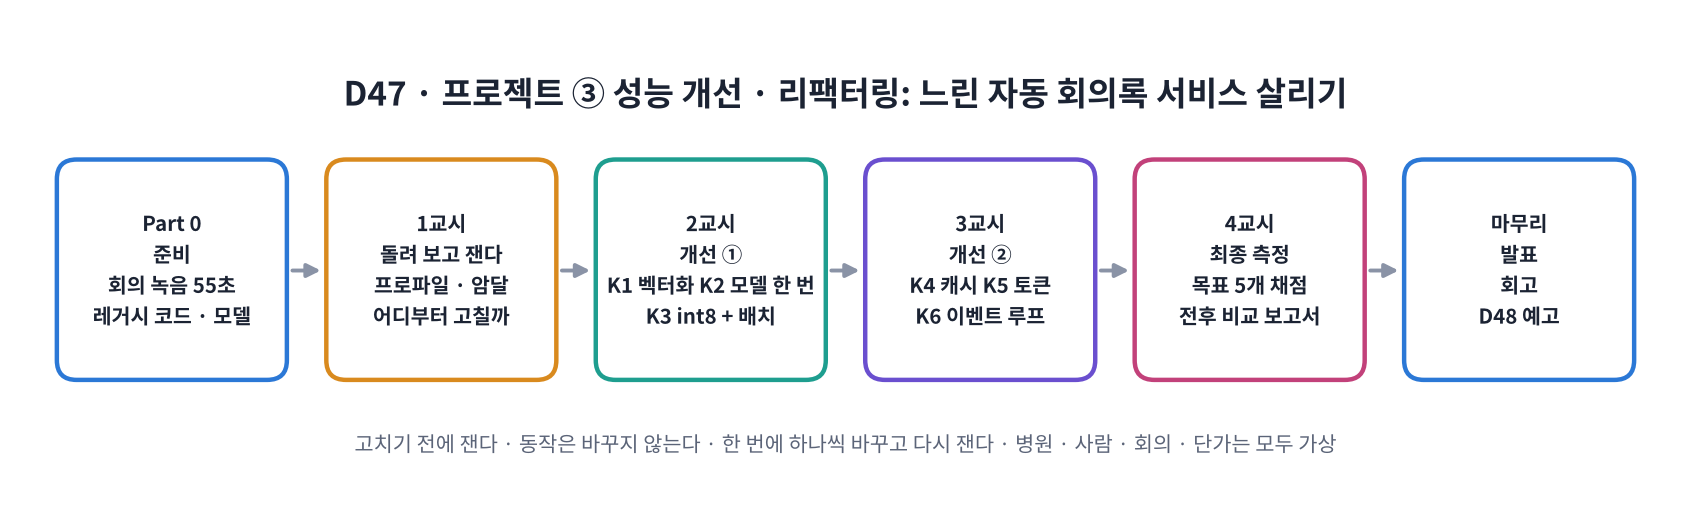

## 오늘은 형식이 또 다릅니다

| | 그제 (D45 따라 만들기) | 어제 (D46 요구사항 명세) | 오늘 (D47 성능 개선 · 리팩터링) |
|---|---|---|---|
| 출발점 | 빈 화면 | 요구서 | **이미 돌아가는 남의 코드** |
| 하는 일 | 단계마다 따라 만들기 | 요구서대로 만들기 | **재고 → 고치고 → 다시 재기** |
| 점수 | 체크포인트 통과 수 | 인수 시험 통과율 | **목표 5개 달성 + 전후 보고서** |
| 가장 중요한 것 | 끝까지 가 보기 | 만들기 전에 묻기 | **고치기 전에 재기** |

## 하루의 흐름

| 교시 | 하는 일 | 내가 쓰는 것 |
|---|---|---|
| 1 | 레거시 서비스 돌려 보기 · 프로파일링 · 어디부터 고칠지 정하기 | ✍️ 가장 느린 단계 찾기 (`share`) |
| 2 | 개선 ① 구간 찾기 벡터화 · 모델 한 번만 올리기 · int8 + 배치 | ✍️ 개선 카드 K1 ~ K3 |
| 3 | 개선 ② 중복 계산 캐시 · 프롬프트 토큰 줄이기 · 이벤트 루프 풀기 | ✍️ 개선 카드 K4 ~ K6 |
| 4 | 최종 측정 → 목표 채점 → 전후 비교 보고서 · 발표 · 회고 | ✍️ 얼마나 줄었나 (`saved`) |

**오늘의 규칙**
- **재기 전에는 고치지 않습니다.** 느려 보이는 곳이 아니라 **재어서 느린 곳**을 고칩니다.
- **동작은 바꾸지 않습니다.** 회의록의 내용(결정 사항 · 할 일)이 그대로여야 합니다. 그것이 리팩터링입니다. 카드마다 "동작이 레거시와 같은가"를 먼저 검사합니다.
- **한 번에 하나씩 바꾸고, 바꿀 때마다 잽니다.** 그래야 "무엇을 바꿔 몇 % 줄었나"를 보고서에 쓸 수 있습니다.
- 쓰지 않은 카드의 자리는 **레거시 코드**가 그대로 맡습니다. 노트북은 끝까지 돌아가지만 그만큼 느리고 비쌉니다.
- 병원 · 사람 · 회의는 모두 **가상**입니다. 단가(원)도 계산 연습을 위한 **가상의 값**입니다.

---
## Part 0. 준비

D44부터 써 온 기기 안 받아쓰기 모델(스트리밍 Zipformer 한국어)을 씁니다. 같은 모델의 **큰 파일(fp32)** 과 **양자화한 작은 파일(int8)** 이 한 꾸러미에 들어 있습니다. 키도 GPU도 필요 없습니다.

> 🎬 **애니메이션 D47-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day47/animation.html#flow)

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1분 안팎)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt soundfile sherpa-onnx==1.13.8
print("✅ 설치 완료")

In [ ]:
import os, re, io, sys, json, time, zlib, base64, tarfile, hashlib, asyncio, warnings, importlib, urllib.request
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import Audio, display, Markdown, HTML
import sherpa_onnx
import importlib.metadata as md
warnings.filterwarnings("ignore")
SR = 16000
print("sherpa-onnx", md.version("sherpa-onnx"), "· CPU", os.cpu_count(), "개")

def verify(cond, what=""):                               # ⭐ 핵심 코드 셀: 결과가 예상과 같은지 스스로 확인
    print(f"✅ 확인: {what}" if cond else f"⚠️ 예상과 다릅니다: {what} → 위 셀을 고쳤다면 원래대로 되돌려 다시 실행하세요.")

def practice(run, want, tol=1e-4):                       # ✍️ 직접 작성 셀 채점: 아직 안 썼거나 오류가 나도 노트북은 계속 실행됨
    try:
        got = run()
    except Exception as e:
        print(f"❌ 실행 중 오류가 났습니다 ({type(e).__name__}: {str(e)[:90]}) · 아래 💡 힌트 보기를 눌러 보세요."); return False
    items = got if isinstance(got, (list, tuple)) else [got]
    if any(x is None or x is Ellipsis for x in items):
        print("✍️ 아직 작성 전입니다. '...' 줄을 지우고 코드를 쓴 뒤 다시 실행하세요. (작성하지 않아도 아래 셀은 그대로 실행됩니다)"); return False
    ok = list(items) == list(want if isinstance(want, (list, tuple)) else [want])
    print("✅ 정답입니다! 🎉" if ok else f"❌ 결과가 다릅니다. 내 결과 {str(got)[:110]} · 기대 {str(want)[:110]} · 아래 💡 힌트 보기를 눌러 보세요.")
    return ok

def play(y, sr=SR, label=""):
    y = np.asarray(y, np.float32).reshape(-1); print(f"🎧 {label}  ({len(y) / sr:.1f}초)"); display(Audio(y, rate=sr))

In [ ]:
# 📼 회의 녹음(가상) 풀기: 한빛치과 주간 회의 55초. 합성한 목소리 세 개로 만든 녹음을 OGG로 담아 두었습니다. (글자가 긴 셀입니다. 실행만 하세요)
_OGG = (
    "..."
    "A5uXGAAzDwA="
)
open("meeting.ogg", "wb").write(base64.b64decode(_OGG))
Y, _sr = sf.read("meeting.ogg", dtype="float32"); assert _sr == SR
SCRIPT = [("원장", "그럼 주간 회의를 시작하겠습니다."), ("접수 담당", "지난주에 받지 못한 전화가 서른 건이었습니다."), ("위생사", "점심시간에는 음성 안내를 먼저 틀면 어떨까요?"),
          ("원장", "좋습니다. 점심시간 음성 안내는 다음 주 월요일부터 하기로 결정합니다."), ("원장", "안내 문구는 박지호 선생님이 금요일까지 작성해 주세요."),
          ("접수 담당", "토요일 오전 예약이 두 주 뒤까지 모두 찼습니다."), ("위생사", "토요일 진료를 한 시간 늘리는 것은 어떻습니까?"), ("원장", "토요일 연장은 이번 달에는 보류하기로 결정합니다."),
          ("접수 담당", "평일 저녁 예약 문자는 이서연 선생님이 수요일까지 보내 주세요."), ("위생사", "소독 기록을 종이에서 태블릿으로 바꾸고 싶습니다."),
          ("원장", "태블릿 기록은 다음 달부터 시범 운영하기로 결정합니다."), ("원장", "태블릿 두 대는 김민준 실장님이 목요일까지 준비해 주세요."),
          ("접수 담당", "네, 목요일까지 준비하겠습니다."), ("원장", "이상으로 회의를 마치겠습니다.")]
REF_TEXT = "".join(t for _, t in SCRIPT)                 # 정확도(CER)를 잴 때 쓰는 정답 대본
play(Y, SR, "한빛치과 주간 회의 (가상 · 합성한 목소리)")
verify(abs(len(Y) / SR - 55.5) < 0.5 and len(SCRIPT) == 14, "회의 녹음 55초와 정답 대본 14줄이 준비됨")

In [ ]:
# 📥 레거시 서비스 코드 풀기 + 받아쓰기 모델 내려받기 (한 번만 · 1분 안팎)
_LIB = (
    "eNqVWl1TG1eavtevOCtf0G1LMuCPTeRiqrI7M1VTlcxsGeZiV9GoGqkFbaSWVmrZIQ5T2FESDKSMx8jGNrDKBBt7h+zIGMdQhfdif0ou1a3/sM"
    "/7ntNfAjsZV4K6z9f7nue836eTyeSgs+kePfGONvqvjoW3vebefSQGj1e9rQ33uy3htdHb9pZ3hOZ2l/ove97KpvDerrv3N3Xxf2/Ery/+sxis"
    "t93vNr3u1mD5UPx076+JhJwv3K+OvK1V8dPXfxHu7hoIif7rvX6vLbze//YPe7Kj98TrtL37Pb+hv9/zuh3h3d4bdH7QPv74E6Yz6HSFt3XMIw"
    "LuMgkw623f87YWQWDb2110d1eFu7zmPtvrv+oK4nz1jruy5K7sZIS3seMubwh0eEfoW130vrzlbX/ld2vuq3vekzUiBtru9iqTlaSW14X738/d"
    "e2ui34tN0xPJZDJhVeu1hiMaZko4VhV/jea8XbRqfofdqtbn0Sjsut/UnDUbdaNQs+3PEonJq2JCjF0eHR1NfDR5tfDr39F7slormZXmeTkyTS"
    "PTTadhGlXLnkl/btXLtUbVbKTnamiz0+Oj4xfTo5fTY5eTicmpj6awws1kpWaUmsmsGE0Jfi40zSK9ZkYXxGn/zvA2vz30ttp4+ka4+0spfvAO"
    "lgRh3VkCjHtu99C9vZH4t6u/+9ffMJ2m2bhuNoLVL4KcZRfG5vB2MUPEay1Hvo5dlrTP+EiSmKw8x4sG8PUsC9x+W4wRRToKIN19KsZSAGfwdX"
    "dwq8etP24OtSYSiTMiHfyLi5XcVKQ7UTLLggExmg1tzrJLE8ly/cJ4Egc4CzhLzYkxPZsgSHC+p6zFAL1Yp5dne97DNUblWY8FiZbLCrmeRgwP"
    "ViFEx7pwN9ZIkgCN80FS8x7cg7YNHq2TXighViMzcrk9lrtve2JM/FmMAxCgJPovDxUhkjzi0BnFGZDcZepmo1wo1lq2YzY0nTvL6KsY1emSIW"
    "yjamZFOXlTydjC+ZvUtJA267XibPrDD9PG9Zn02M2RDDE4Iqwyb0VMTIgR2QJxNMXIyEKGhFESB36gEJHmzB/simWbV81ibca2PjcbmXKjVi04"
    "DcNullpFMObU5ky7ORFlRDZlnM8cnIBpFyH5jYmyllSPST0lSmbQqh6p9VoNtLhRPqEtERVoaF7BP1H1mxJNo1qvmIWG4ZgTk1dTomwaTqthFk"
    "pWdeKDUUUKSlaoms5sDaIx0zDN0jzE22gUZ5MSWNKxnFKwvDgH/b0SaWNV4OZTDkakcWa8SMMEYZtAhPySTNbqpl2QWq6hNSXmQzH0vl6FTAgW"
    "l+96/d4tqaUsjpBAt/09NXg7izB77tNjGggx0bzOtvuXHZbR3V22lHsHsMo8+UdYz7YeSFITRwmqmSLoO6bPh9xvM2MUi2bdKdwwrptkejSCzq"
    "5nijW7iNE2/tdyeMeR15roFOfPi3EeUQYizoVxnV+MptFoGPPa/MkuOROiRrPPwo58oMcG5XWfFcuuw6CULduC5JUUhwrMpoJSSglk0vx5JKXj"
    "OVyMIXHKWXDfjVmrYjJOVrNAIjWvNdXaSiMyiraa3NSHDjszYzqY2WxVHOocMl1jmdO9ZcR8/fbqR5+Q5b0wPir+oX9nBGZUfYjKDeh/wYTezO"
    "BAQnx4jILG3SU/JyRkZK0Ht/bAjXb1k0mdpMzbjhkjGHrwlctL41NrCEtYtoDyz5haxbRBheSC+Y9g5tQco4J5cExBG02+Fk5WU967t8G9TffV"
    "Ic51A+7JW38B47kutSBmFCQ16CYLljafsyBtEtJz4lpeF2fPivFgBnaUMeqQhZKmyZk+/zRuNHMpdroY7YML2wkzMFM1baepSZDZvUxgl1AMuP"
    "FC06pMjF9KibpRmrgU4i8hJmuP4QSy2+YYJFR7b/sbxDEpIg+/oI1fkl06jezvr9JI7/ELAuLFAXzhpvdAuqxby1iHvRRJfE5DNAfXo4CDq7+1"
    "pZ71fKAKdVhuGE3HaDgp8Z8ty5QnnBK/h26BhfCoYbvpwExYXZOsq1axmo7aug5sc9h5Hlhrau9oGtMjYgCPY4pf0aazsQNDO5MXVpOJZtXrhL"
    "Bi43zmQiEyK9G5ds2R80+ZRRZ8mKjs+ZV/VPFpATaBdFSNz7RRhRRsPA5V9wUrJTQLTYoUHPq5WLeuXxkGOAqub9mI2rC1GM/EY52hIIf9brFh"
    "TZsaZBHnSKYHJmjCj36iYQ6Jia/293d8owgf84KC7XeqOBamY6f1Y2YQoxQ1TUZD+vtNU8zghHGW9GhDehzRymFDDz70U3QyhtqFTDzPEDLRiI"
    "B39Y8f/2aSwnAAs3LkrXQ5PovkSmwLwzwJAVz7JevY3Q7Hbbs73uOe8Da77vJTKCLlI94RsqQldjtbh/1XrylhWX7KaUp7M5KK4DTd7Q0igBHe"
    "0XNaVho19y4IHHW93TXv4dfe1oHoHx/jP1qftH7rLac9vQ2kZ5yoYfoxfr4/xhtHr711d/tbRSfh7f/N24Xay20gRAAbgkznxvOI0fD2wcqq++"
    "PioN0jC9E/WsW6vCg47B8tK9LegwNJ6QeyKhvYh3tvg9dXkkUR/+MDCmgpBHn4DYHQW5Shyga4QxIpcCTs+aKHQ0ld/9VzF+lfbP2E99UKrx8b"
    "TagQgCvE1CGlcrtrKSCx5O5hKFju7++BpVcHgIqNancJuSDRHtzF/OfghbYHMYzupP3mNEqLPkwUfync9g697aeEGyeaaq01Opf+m0NFydv4n/"
    "7+86Hd4Ei89t9P31B4+nTum8dk1vGEKbQLSnpXXg86w/h7D/f8FdGvBLj/+gecFLhIyQBop03chz7T6946cZLMG+SJ5H9/CQfZga4OOi98gX3v"
    "cW2ypwqBIr5JQW4fwEURU+EJkLyCN/ScOAEC4stbLB+POkqfEByBshL+KAKbhE+/t8YMobfrLb8OhH53sX+45Avx43Wv85Zw8NnBCttLiBvAPs"
    "PNqvhObZCwKL0bOrV20N3tIHY6cTxkT2WoMN2yKqVCHXlSHaECpU/NYbMcCoGgIobbWZV2ErJyeKDMBBdwIrvj3FoZ9W4bLHMoIXmC/Lu3D4NI"
    "gEs4e/hLJRxp7zXCnyoqd6TwgMrrTe+vX9E2QUn33YFiO+4S5sLAbSwlKPCTu2KPHzoJNde35NLmnhPJT+2k+slQXqcl04IamtLd0Nq8XC47l4"
    "+berWgwpUzroJMLjXH/MyJhFiyluAtsZntvznGqWVZPQ5ZS8jxIT3nYsMGK4R7+yX02D8Eal/6G40IG2DCBht++ElYj0kqpK8k3O1jzsdwAF2o"
    "EnXtkc5tHXjdRe/RIivFyo779IAKS4G7VTsjDBtmhqJKo1LRGskcbGd6sP19/ovcR+n/MNKf58998Wnpi9yfPm1+eiNPlQzasK6gqFSqmgQnxA"
    "AuTwy27kDytf6bTe/oEcLrkbQYYWY5MKStEFdKiHbaERs+IsV9hCQD0QLbDGgOWVSYFLJ/gblz76663R3y4yRvg9s7rFlbh1AhGFZ+ud9jdez4"
    "8am/+1lLilbFzo1n8xlkVFYdGTTJQcUmQZCbyjTrFcthoUAvQreKneGAqnnDcmZZfnRhoJiRlFwnWYbsTMOsV4yiqSUFAEsm9XwU8lD+iAtelt"
    "nhMkiSHfCqr8KNll0IMUac1WqaEWmLqBcnTb3n7ncSGtLDA/bacXVrD6Hm3T8QSpzQh9XZ5/j5TYAXor0bJkVeAX++StZDtKJhmj+emdeDdhDI"
    "JYuQtLC6wU2WLd9jqlXXVS8irVO6JY2YnubyhKZPPORWYivbY2c6HMBdzAQl4aGIl/Mup1aqnbCkIz89XJH/QRe73pdb7soGq+P2UzzpJMjoI5"
    "ewdaz8w0+Lz9hotw/RPIJo6yA0qn68tAJ9PSLbS/rf2eSje3tvSI6ZoaGwObBjkUSYimknpDLorqIbRkAWomADtMAI3LywoGvBrr6I7UrLeU/W"
    "UWiEsYNph3uAHGGLeblTXW6VDIYezcSqUl+C3bPKONmhTBq78q33zeSN2RpKvNXMTKPWqmtjqN4kSy0z0nSBmm7MGg7anIWYRPBSw6d8KUNJgf"
    "vs7fAhN8yqWZ1GMa1sh+cb3lDo7Lf3Dvr7X5J1wcF4D16rwC60McJ3ib4zFWU76rZXdgYP7gzpl+K2bINVrvILYmcWUFVM7VptOlZnijEEsPdl"
    "VIB0TUZwsJB848IlZJIlHIdM07eUcx4iCwKooID075E0UnaSS0ZrOCQtKuOixzD3ozcfMnqOBRzUIDeQzCtrVjXmqHplzED1kPyaE5SNRkISWC"
    "wUJ9gkdZ5DrHgQl4PcW8dIezjiC206B3m8T/YmQ/dI7G5etsmtRHY8yRcLsd1lYwWryF6zQS0/vuusyqLDvWcDyTmBQjYehoWgZNXxLki+Mq16"
    "iWobN+ey4roMdlJ4gHIwCgINNxf0jOWYVeWLOBiSJ0YqRVbVmIa4XNeVCmDMZC7KeD6odATqNmMAEIzy95y/cmJOUOnnTPyU1N+Iadxk9LDBes"
    "vBaQPWyQmJ2pT6hWUfPv/wXi+8ixOTWb7JedVWQoGgAIv4jS7a5d0FxRaI3DmY7nI1q2QVHaaTFRSTIBRDKO7+152hIVHRmCSco2IKF0R3XlME"
    "5lS02CNdys0FdlEYQX8xhn9OjFIuT96YwdfJB3JreFpIMHmOLCu14pxG1ye4PrBT4qwRrWa+40LmiqhQz/AtwRVB/rdsa1jkiiiJd98ZoLdyyg"
    "Loq4Qlr6kcsUXSMEV1ZsUkKm8UfJcwtlQBVLmkuhSTN02wkMlwysm+cIFKQEiJUSNEhcp9XOPN/uJytCrFy5tgWSUIKk5hFY8VHuxJ2JOxujh4"
    "mxwyg/mgVh8U6QjhUwqy+vBuFIVoSU0SiGpaSuTmc0Z2Os/qb6TENNe/iE5el3BIKKTKBtYnr8lmXQ2B6yel9VH7ZYidzDLf3iN/0t3hKPL+99"
    "K7qUMpWk2rxttXO2MF46wX+1JRK28wbg3zKniSgWzI7/g/yPAZP0w7wakWzaT1IC+N8e9HTcMx3XjMkOGemxrJDdAvRR3+vtEWPJNvoCUo9qBf"
    "vMsLa4QmCF/82wlB91pj+oKfQ0L7GmY5JWbn60rH4TtmyfdSJNaaplTsT6PpD2US5sdjHLihFqmHoV64jIwBSwpKLbwdmZUJsh4tqRvxknojNZ"
    "RBm9dxY5kbJe2ln1SkJs5XKEo6wxVm4ytEV7kmV7mW5+sJjRvAEHfBcoypNxqOJ80Q/zQhpuMZeCmXxrDzgorhKvVvBFlo1TSauGklLxOEFZBC"
    "s1ygZHUCoW54R8eFDK6B+p+gcI3O9zeyJrpJnyggdVqFs+EKK7sWSsZpyuMXnKdzyQhx4CnXVeRKhoMd5UlCj/EzXuGEWYf2JN7vB6o+2ajbhb"
    "OU2oa7ALMofubqGLQofHR7D9hw890DfWpBU9Oi2apqU5nrRqVFrtG/N+WvNCjDwJizgj/fyEW/3YArQsomfaRK9c6LMXxjEY6Wn3WQHEQSvuFB"
    "6muPfFxJpbLhLykew43XKfVlCj3Hr9TJqaHThz6akLImzxX4JAJWVaM8lZC5+PcAyWKt6RTklpkZekipZlhCtg1zqiEYgN2qVp6lTALLLKm5rB"
    "FUc8oMoSRFAYY/QkYWLOlxVuxCiREhFcHk0GblKUuy2d6F3dJ0cZcSGsqr8Ga0SlZNfXoTsWELw7nU5Yz6toZCd/fFkvfjOiwtR+jbe0M3R4V/"
    "+ePkv7MOBBXK5nxBZh+hhspCVtRVkob6H6vIaI8jfph/jSnukIIOHm5AM/GRiyqxUahImUO03OHrJ3BMUrTLcRqsGDOWlT857uGw1/+SR35aQ/"
    "Ytdm8GZSBkIhdF0QUoWJBmuhBWLcfZZoUZXqVWqxdmjLomc4ECBX0RLIJWzUeKuhlp2B1KevjjKQ6jCBz/kusJEtMDr8M3IIzUyh7ydmDaoQl0"
    "v4N6Gxr6h4dc4yYQN5SV07COznUHLsi+E8Pw7HLZyat5/ZeGZpEvnf5OJym//ALT9wL/DEDgRo2Kdd1Ud8JTjZaZUF8G+dhN42sSLeJxKkbTec"
    "8nS5FvLGjhuKcybhiW439fl2lWTLNOdm9cj3/2U7vxLtNLLPsVCxqWZnYoNpdcoU3y7xjNOf4eRpJCIYu+ESq36FMhTW4Js07nJ5A/+sSDFuFR"
    "pwtJ4j3bukQUFLq/NWBHfILEXFTEyfzTzvSUIpr4fwYzFo8="
)
open("slow_minutes.py", "w", encoding="utf-8").write(zlib.decompress(base64.b64decode(_LIB)).decode("utf-8"))
import slow_minutes as sm; importlib.reload(sm)
from slow_minutes import load_asr, open_stream, decode_one, FRAME
print(f"레거시 서비스: slow_minutes.py ({len(open('slow_minutes.py', encoding='utf-8').read().splitlines())}줄)")

REL = "https://github.com/k2-fsa/sherpa-onnx/releases/download"
os.makedirs("models", exist_ok=True)
if not os.path.exists(sm.ASR_DIR):
    t0 = time.time(); tmp = "models/zipformer.tar.bz2"
    urllib.request.urlretrieve(f"{REL}/asr-models/sherpa-onnx-streaming-zipformer-korean-2024-06-16.tar.bz2", tmp)
    with tarfile.open(tmp) as tf: tf.extractall("models")
    os.remove(tmp); print(f"받음: 받아쓰기 모델 ({time.time() - t0:.0f}초)")
size = lambda kind: sum(os.path.getsize(f"{sm.ASR_DIR}/{n}-epoch-99-avg-1{'.int8' if kind == 'int8' else ''}.onnx") for n in ("encoder", "decoder", "joiner")) / 1e6
print(f"모델 파일 크기: fp32 {size('fp32'):.0f} MB · int8 {size('int8'):.0f} MB")

SEGS = [Y[a:b] for a, b in sm.find_segments(sm.frame_energy(Y))]      # 발언 조각 (검사할 때 씁니다)
CLIP = SEGS[3]
_asr = load_asr("int8"); print("조각 하나 받아쓰기:", decode_one(_asr, CLIP)); del _asr
verify(len(SEGS) == 14 and size("int8") < size("fp32") * 0.6, "레거시 서비스 코드와 받아쓰기 모델(fp32 · int8)이 준비됨 · 녹음에서 발언 14개를 찾음")

---
## Part 1. (1교시) 레거시 서비스를 받다: 돌려 보고, 재고, 계획한다

> 💬 **쉽게 말하면**: 오늘은 아무것도 새로 만들지 않습니다. 전임자가 남긴 **돌아가는 코드**를 받았습니다. 느리고 비쌉니다. 고치고 싶은 곳이 눈에 띄어도 참고, **먼저 잽니다.** 어디가 느린지는 읽어서는 알 수 없고 재야 압니다.

### 📨 인수인계 메모 (가상)

> **보내는 사람**: 전임 개발자 · **받는 사람**: 여러분
>
> 한빛치과 자동 회의록 서비스를 넘깁니다. 회의 녹음을 올리면 **결정 사항**과 **할 일(담당 · 기한)** 을 뽑아 줍니다. 결과는 맞습니다. 다만 느립니다. 1시간짜리 회의를 올리면 회의보다 오래 걸립니다. 그동안 접속 확인(`/health`)에도 답을 못 합니다. LLM 요금도 생각보다 많이 나옵니다. 시간이 없어서 못 고쳤습니다. 코드는 `slow_minutes.py` 한 파일입니다.

### 🎯 원장님의 목표 (가상)

| # | 목표 | 기준 |
|---|---|---|
| ① | **처리 시간** | 지금의 **1/12 이하** (1시간 회의가 1시간 넘게 걸리던 것을 몇 분으로) |
| ② | **비용** | 지금의 **1/3 이하** (서버 시간 + LLM 토큰) |
| ③ | **정확도** | 받아쓰기 글자 오류율(CER)이 지금보다 **2%p 넘게 나빠지지 않을 것** |
| ④ | **서버 응답** | 회의록을 만드는 동안에도 서버가 **0.1초 넘게 멈추지 않을 것** |
| ⑤ | **내용** | 결정 사항과 할 일의 수가 **지금과 같을 것** |

목표는 **이 노트북에서 잰 레거시의 값**에 견준 비율입니다. 컴퓨터가 달라도 공평합니다.

### 레거시 코드의 구조

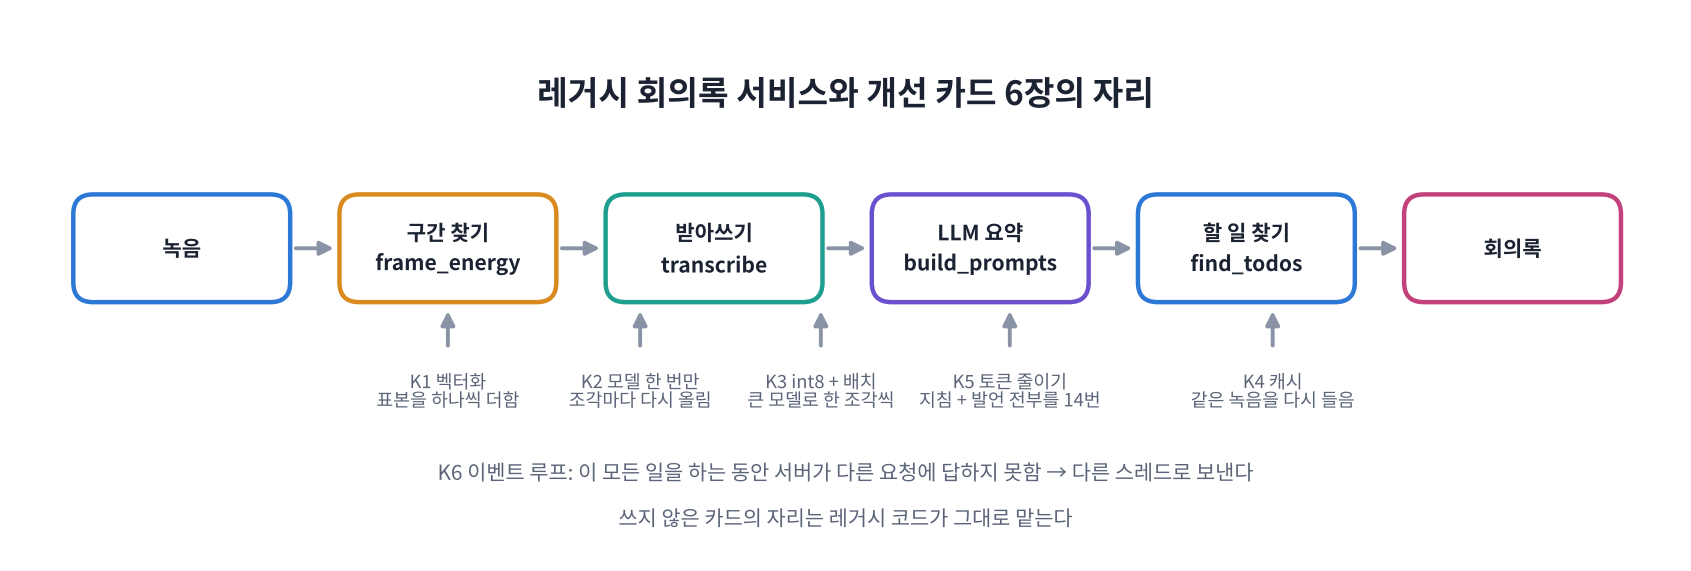

```
녹음 → ① 구간 찾기(frame_energy → find_segments) → ② 받아쓰기(transcribe) → ③ LLM 요약(build_prompts → llm) → 결정 사항
     → (할 일을 뽑으려고 ①②를 다시) → ④ 할 일 찾기(find_todos) → 회의록
```

코드를 읽어 보려면 새 셀에서 `print(open("slow_minutes.py", encoding="utf-8").read())`를 실행하세요. 8분 동안 읽으며 **"어디가 느릴까?"를 짐작해 적어 두세요.** 조금 뒤에 잰 값과 견줍니다.

> ⚠️ **LLM은 흉내입니다.** `llm()`은 키도 인터넷도 쓰지 않고, 규칙으로 '결정'이 들어 있는 발언을 골라 줍니다. 그래서 LLM의 **시간은 재지 않고, 토큰 수로 비용만** 셉니다. 토큰 수도 근사(한글 한 글자를 1토큰으로)입니다.

> 🎬 **애니메이션 D47-2:** [레거시 서비스와 프로파일](https://imguru-mooc.github.io/AI_Voice/day47/animation.html#profile)

In [ ]:
# ⭐ 레거시 서비스를 그대로 한 번 돌리며 잰다 (약 1분 ~ 1분 30초 걸립니다. 그 느림이 오늘의 과제입니다)
CALLS = {}
def spy(name):                                           # ⭐ 작은 프로파일러: 함수를 감싸 '몇 번 불렸고 모두 몇 초 걸렸나'를 적는다
    fn = getattr(sm, name)
    def wrapper(*a, **k):
        t0 = time.perf_counter()
        try: return fn(*a, **k)
        finally:
            c = CALLS.setdefault(name, [0, 0.0]); c[0] += 1; c[1] += time.perf_counter() - t0
    setattr(sm, name, wrapper); return fn
SPIED = ["load_asr", "decode_one", "frame_energy", "find_segments", "llm", "find_todos"]
_orig = {name: spy(name) for name in SPIED}              # ⭐ 레거시의 함수 여섯 개에 시계를 단다
BASE = sm.measure(Y, None, REF_TEXT)                     # ⭐ 레거시 그대로(None) 한 번 실행: 시간 · 비용 · 정확도
for name, fn in _orig.items(): setattr(sm, name, fn)     # 시계를 뗀다

def show_minutes(m):
    print("📋 결정 사항"); [print("   -", d) for d in m["decisions"]]
    print("📋 할 일"); [print(f"   - {t['who']} · {t['due']}까지 · {t['what']}") for t in m["todos"]]
show_minutes(BASE["minutes"])

stage = pd.DataFrame([{"단계": k, "걸린 시간(초)": round(v, 2), "비중(%)": round(v / BASE["sec"] * 100, 1)} for k, v in BASE["stages"].items()])
display(stage)
print(f"처리 시간 {BASE['sec']:.1f}초 (녹음 {BASE['audio_sec']:.1f}초) → 1시간 회의라면 약 {BASE['sec'] / BASE['audio_sec'] * 60:.0f}분")
print(f"모델을 올린 횟수 {BASE['loads']}번 · LLM 호출 {BASE['calls']}번 · 토큰 입력 {BASE['tok_in']:,} + 출력 {BASE['tok_out']:,}")
print(f"비용 {BASE['cost']:.1f}원 = 서버 {BASE['cost_server']:.1f}원 + LLM {BASE['cost_llm']:.1f}원 (가상의 단가) · 글자 오류율 CER {BASE['cer'] * 100:.1f}%")

display(pd.DataFrame([{"함수": k, "부른 횟수": c, "모두(초)": round(t, 2), "한 번에(초)": round(t / c, 3)} for k, (c, t) in sorted(CALLS.items(), key=lambda kv: -kv[1][1])]))   # ⭐ 오래 걸린 차례로
verify(BASE["n_dec"] == 3 and BASE["n_todo"] == 3 and BASE["loads"] >= 20, "레거시 서비스가 회의록(결정 3 · 할 일 3)을 만들었고, 단계별 시간과 비용을 잼")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
_orig = {name: spy(name) for name in SPIED}
BASE = sm.measure(Y, None, REF_TEXT)
display(pd.DataFrame([{"함수": k, "부른 횟수": c, "모두(초)": ..., "한 번에(초)": ...} ...]))
```

**해설**: 재는 방법은 두 가지를 함께 씁니다.

- **단계별 시계**(`measure` 안의 `clock`): 서비스의 큰 단계마다 걸린 시간을 더합니다. "어느 단계가 느린가"를 봅니다.
- **함수별 시계**(`spy`): 함수를 감싸 **몇 번 불렸고 모두 몇 초 걸렸는지**를 적습니다. "그 단계 안에서 어느 함수가, 몇 번 불려서 느린가"를 봅니다. 프로파일러가 하는 일을 손으로 만든 것입니다.

표를 읽어 보세요. 짐작과 같았나요? 많은 사람이 "표본을 하나씩 더하는 이중 반복문"(`frame_energy`)을 가장 느린 곳으로 꼽습니다. 재 보면 전체의 1%도 되지 않습니다. 시간의 대부분은 **모델을 올리는 일**(`load_asr`)에 들어갑니다. 한 번에 2초쯤인데 **28번** 불렸습니다. 발언이 14개인데 28번인 까닭도 표에서 찾아보세요(힌트: `frame_energy`도 두 번 불렸습니다).

**"한 번에 몇 초"와 "몇 번"을 따로 봅니다.** 한 번이 느린 함수는 그 함수를 고치고, 한 번은 빠른데 너무 많이 불리는 함수는 **부르는 쪽**을 고칩니다. `load_asr`는 뒤쪽입니다.

`measure`의 두 번째 인자가 오늘의 손잡이입니다. `None`이면 레거시 그대로, 내가 쓴 함수들을 주면 그 자리만 바꿔 끼워 잽니다.

> 파이썬에는 `cProfile`이라는 프로파일러가 들어 있습니다(`python -m cProfile -s tottime 파일.py`). 스크립트를 통째로 잴 때 씁니다. 노트북에서는 뒤에서 도는 다른 스레드의 시간이 표에 섞여 읽기 어려워, 오늘은 필요한 함수에만 시계를 달았습니다.

</details>

### 프로파일을 읽는다: 어디부터 고칠까

단계별 시간표에서 **가장 큰 덩어리**를 찾는 일이 성능 개선의 첫걸음입니다. 사람 눈으로도 보이지만, 보고서에 쓸 숫자로 뽑아 봅니다.

In [ ]:
# ✍️ 직접 작성 1: 가장 느린 단계 찾기
# times는 {"단계 이름": 걸린 시간(초)} 딕셔너리입니다. (가장 오래 걸린 단계의 이름, 그 단계가 전체에서 차지하는 비중 %)를 돌려주세요.
# 비중은 소수 첫째 자리로 반올림합니다. 예: {"가": 1.0, "나": 3.0} → ("나", 75.0)   (3줄)
def share(times):
    ...                                                  # ← 이 줄을 지우고 작성하세요

W1_OK = practice(lambda: [share({"가": 1.0, "나": 3.0}), share({"구간 찾기": 0.3, "모델 올리기": 48.0, "받아쓰기": 19.2, "LLM 요약": 0.5})], [("나", 75.0), ("모델 올리기", 70.6)])
if W1_OK: print("레거시에서 가장 느린 단계:", share(BASE["stages"]))

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 전체 시간: `total = sum(times.values())`.
2. 값이 가장 큰 열쇠: `name = max(times, key=times.get)`.
3. `return name, round(times[name] / total * 100, 1)`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def share(times):
    total = sum(times.values())
    name = max(times, key=times.get)
    return name, round(times[name] / total * 100, 1)
```

**해설**: `max(times, key=times.get)`는 "값이 가장 큰 열쇠"를 고르는 파이썬의 관용구입니다. 이 한 줄이 오늘의 방향을 정합니다. 전체의 70%를 쓰는 단계를 절반으로 줄이면 전체가 35% 줄지만, 1%를 쓰는 단계는 **없애도 1%** 입니다. 다음 셀에서 이것을 계산으로 확인합니다.

</details>

In [ ]:
# ⭐ 암달의 법칙: 한 단계를 빠르게 해도 전체는 그 단계의 비중만큼만 빨라진다
def amdahl(p, s):                                        # ⭐ p: 그 단계의 비중(0 ~ 1), s: 그 단계가 빨라진 배수 → 전체가 빨라지는 배수
    return 1 / ((1 - p) + p / s)

plan = []
for name, sec in BASE["stages"].items():
    p = sec / BASE["sec"]
    plan.append({"단계": name, "비중(%)": round(p * 100, 1), "이 단계만 10배 빨라지면 전체는": f"×{amdahl(p, 10):.2f}",
                 "이 단계가 0초가 돼도 전체는(한계)": f"×{1 / (1 - p):.2f}" if p < 0.999 else "-"})   # ⭐ s가 무한대일 때의 한계 = 1 / (1 - p)
display(pd.DataFrame(plan))
print(f"목표 ①은 ×12. 받아쓰기만 아무리 빠르게 해도 한계는 ×{1 / (1 - BASE['stages']['받아쓰기'] / BASE['sec']):.2f}입니다.")
verify(abs(amdahl(0.5, 2) - 4 / 3) < 1e-9 and amdahl(0.01, 100) < 1.011, "비중 50%인 단계를 2배 빠르게 하면 전체는 1.33배 · 비중 1%인 단계는 100배 빠르게 해도 전체는 1.01배")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
def amdahl(p, s):
    return 1 / ((1 - p) + p / s)
```

**해설**: 전체 시간을 1이라고 하면, 고치지 않는 부분은 `1 - p` 그대로 남고 고친 부분은 `p / s`로 줄어듭니다. 둘을 더한 것이 새 전체 시간이고, 그 역수가 "전체가 몇 배 빨라졌나"입니다.

표의 마지막 열이 중요합니다. 한 단계를 **아무리** 빠르게 해도 전체는 `1 / (1 - p)`배를 넘지 못합니다. 그래서 순서는 이렇게 정합니다.

1. **비중이 큰 단계부터.** 지금은 '모델 올리기'입니다.
2. 그 단계를 줄이고 나면 **다시 잽니다.** 비중이 바뀌어, 다음으로 큰 덩어리가 달라집니다.
3. 비중이 작은 단계는 코드가 아무리 눈에 거슬려도 **뒤로 미룹니다.**

오늘의 카드 K1(이중 반복문을 numpy로)은 일부러 넣은 **함정**입니다. 그 단계는 50배 넘게 빨라지지만 전체는 거의 그대로입니다. 직접 해 보고 숫자로 확인하세요.

</details>

In [ ]:
# ⭐ 오늘의 도구: 개선 카드 검사 · 등록(card) · 측정판(bench) · 목표 채점(scorecard)
MINE, WRITTEN, HISTORY, _SEEN, GAP, _WANT, SUBMITS = {}, set(), [], {(): BASE}, {}, {}, 0
TARGET = {"time": 12, "cost": 3, "cer": 0.02, "gap": 0.1}

def _report(no, name, fn, state, msg):
    if state != "ok": MINE.pop(name, None); WRITTEN.discard(name)
    if state == "blank": print(f"✍️ [K{no} {name}] 아직 작성 전입니다. 쓰지 않으면 이 자리는 레거시 코드가 맡습니다. (아래 셀은 그대로 실행됩니다)")
    elif state == "bad": print(f"❌ [K{no} {name}] 동작이 레거시와 다릅니다: {msg} · 아래 💡 힌트 보기를 눌러 보세요.")
    else: MINE[name] = fn; WRITTEN.add(name); print(f"✅ [K{no} {name}] 동작이 레거시와 같습니다. 서비스에 끼웠습니다 · 효과: {msg}")   # ⭐ 동작이 같아야만 끼운다
    return state == "ok"

def card(no, name, fn, check):                           # 개선 카드 하나를 검사하고, 통과하면 서비스에 끼운다
    try: state, msg = check(fn)
    except Exception as e: state, msg = "bad", f"실행 중 오류 ({type(e).__name__}: {str(e)[:100]})"
    return _report(no, name, fn, state, msg)

async def card_async(no, name, fn, check):
    try: state, msg = await check(fn)
    except Exception as e: state, msg = "bad", f"실행 중 오류 ({type(e).__name__}: {str(e)[:100]}) · async def로 썼는지 확인하세요"
    return _report(no, name, fn, state, msg)

def chk_energy(fn):
    y3 = Y[:SR * 3]; got = fn(y3)
    if got is None: return "blank", ""
    want = sm.frame_energy(y3)
    if len(got) != len(want) or not np.allclose(np.asarray(got, float), want, atol=1e-6): return "bad", f"조각 수 {len(got)}개(기대 {len(want)}개)이거나 값이 다릅니다"
    t0 = time.perf_counter(); fn(Y); mine = max(time.perf_counter() - t0, 1e-6); old = BASE["stages"]["구간 찾기"] / 2
    return "ok", f"구간 찾기 한 번 {old:.2f}초 → {mine:.4f}초 (×{old / mine:.0f}) · 그런데 이 단계는 전체 {BASE['sec']:.0f}초의 {old * 2 / BASE['sec'] * 100:.1f}%뿐입니다"

def chk_asr(fn):
    n0 = sm.STAT["loads"]; a = fn("int8")
    if a is None: return "blank", ""
    b, c, d = fn("int8"), fn("fp32"), fn("fp32"); n = sm.STAT["loads"] - n0
    if not hasattr(a, "create_stream"): return "bad", "받아쓰기 모델이 아닌 것을 돌려주었습니다"
    if a is not b or c is not d: return "bad", "같은 kind로 두 번 불렀는데 모델을 다시 올렸습니다"
    if a is c: return "bad", "int8과 fp32가 같은 모델입니다. kind마다 따로 넣어 두세요"
    t0 = time.perf_counter(); fn("int8"); again = time.perf_counter() - t0
    return "ok", f"네 번 불렀는데 올린 것은 {n}번 · 다시 부르면 {again * 1000:.2f} ms (레거시는 부를 때마다 약 {BASE['stages']['모델 올리기'] / BASE['loads']:.1f}초)"

def chk_transcribe(fn):
    segs = SEGS[:4]; got = fn(segs)
    if got is None: return "blank", ""
    if not _WANT:
        for kind in ("int8", "fp32"):
            asr = load_asr(kind); _WANT[kind] = [decode_one(asr, s) for s in segs]
    got = list(got)
    if got not in _WANT.values(): return "bad", f"받아쓴 글이 다릅니다. 내 결과 {str(got[:2])[:70]} · 기대 {str(_WANT['int8'][:2])[:70]}"
    t0 = time.perf_counter(); fn(SEGS); mine = time.perf_counter() - t0; old = BASE["stages"]["받아쓰기"] / 2
    msg = f"발언 {len(SEGS)}개 받아쓰기 {old:.1f}초 → {mine:.1f}초 (×{old / mine:.1f})"
    return "ok", msg + (" ⚠️ 거의 빨라지지 않았습니다. int8 모델과 decode_streams(여러 조각을 한꺼번에)를 썼는지 보세요." if mine > old * 0.6 else "")

def chk_remember(fn):
    calls = []
    def slow(y): calls.append(1); return float(np.sum(y))
    w = fn(slow)
    if w is None: return "blank", ""
    a = np.arange(8, dtype=np.float32); r1 = w(a); r2 = w(a.copy()); same = len(calls); r3 = w(a + 1)
    if not (r1 == r2 == 28.0 and r3 == 36.0): return "bad", f"돌려준 값이 fn의 결과와 다릅니다 ({r1}, {r2}, {r3} · 기대 28.0, 28.0, 36.0). 소리가 다르면 다시 계산해야 합니다"
    msg = f"내용이 같은 소리를 두 번 주었더니 fn을 {same}번 실행 (레거시는 2번)"
    return "ok", msg + (" ⚠️ 줄지 않았습니다. 소리의 '내용'으로 열쇠를 만들어 store에 넣어 두세요." if same != 1 else "")

def chk_prompts(fn):
    lines = BASE["minutes"]["lines"]; ps = fn(lines)
    if ps is None: return "blank", ""
    if not isinstance(ps, list) or not all(isinstance(p, str) for p in ps): return "bad", "프롬프트(문자열)를 담은 리스트를 돌려주세요"
    use = {"calls": 0, "in": 0, "out": 0}; ans = sm.run_llm(ps, use)
    if ans != BASE["minutes"]["decisions"]: return "bad", f"LLM의 답이 달라졌습니다(결정 사항 {len(ans)}개 · 기대 {BASE['n_dec']}개). 발언은 모두 '- '로 시작하는 줄로 넣어야 합니다"
    old, new = BASE["tok_in"] + BASE["tok_out"], use["in"] + use["out"]
    msg = f"LLM 호출 {BASE['calls']}번 → {use['calls']}번 · 토큰 {old:,} → {new:,} (−{(old - new) / old * 100:.0f}%)"
    return "ok", msg + (" ⚠️ 거의 줄지 않았습니다. 한 번만 보내고 지침을 짧게 써 보세요." if new > old * 0.5 else "")

async def chk_handle(fn):
    gap, got = await sm.loop_gap(fn, CLIP)
    if got is None: return "blank", ""
    if "legacy" not in GAP: GAP["legacy"], GAP["want"] = await sm.loop_gap(sm.handle, CLIP)
    if got != GAP["want"]: return "bad", f"돌려준 값이 job(y)의 결과와 다릅니다 ({got} · 기대 {GAP['want']})"
    msg = f"일하는 동안 서버가 가장 길게 멈춘 시간 {GAP['legacy']:.2f}초 → {gap:.2f}초"
    return "ok", msg + (" ⚠️ 여전히 멈춥니다. 일을 다른 스레드로 보냈는지 보세요." if gap > TARGET["gap"] else "")

def bench(label):                                        # 지금까지 끼운 카드로 서비스를 한 번 돌려 잰다
    sig = tuple((k, id(v)) for k, v in sorted(MINE.items()) if k != "handle")
    if sig not in _SEEN: _SEEN[sig] = sm.measure(Y, MINE, REF_TEXT)   # ⭐ 바뀐 카드가 없으면 다시 재지 않는다
    else: print("(끼운 카드가 지난 측정과 같아, 지난 측정값을 다시 보여 줍니다)")
    r = _SEEN[sig]
    HISTORY[:] = [h for h in HISTORY if h["label"] != label] + [{"label": label, "cards": sorted(WRITTEN), "r": r}]
    display(pd.DataFrame([{"측정": h["label"], "끼운 카드": len(h["cards"]), "처리 시간(초)": round(h["r"]["sec"], 1), "빨라진 배수": f"×{BASE['sec'] / h['r']['sec']:.1f}",
        "1시간 회의라면(분)": round(h["r"]["sec"] / h["r"]["audio_sec"] * 60, 1), "비용(원)": round(h["r"]["cost"], 1), "비용 비율": f"{h['r']['cost'] / BASE['cost'] * 100:.0f}%",
        "CER(%)": round(h["r"]["cer"] * 100, 1), "모델 올린 횟수": h["r"]["loads"], "LLM 토큰": h["r"]["tok_in"] + h["r"]["tok_out"]} for h in HISTORY]))
    print("단계별(초):", " · ".join(f"{k} {v:.2f}" for k, v in r["stages"].items()))
    return r

def scorecard(r, gap):                                   # 목표 5개 채점
    rows = [("① 처리 시간", f"레거시의 1/{TARGET['time']} 이하 (≤ {BASE['sec'] / TARGET['time']:.1f}초)", f"{r['sec']:.1f}초 (×{BASE['sec'] / r['sec']:.1f})", r["sec"] <= BASE["sec"] / TARGET["time"]),
            ("② 비용", f"레거시의 1/{TARGET['cost']} 이하 (≤ {BASE['cost'] / TARGET['cost']:.1f}원)", f"{r['cost']:.1f}원 ({r['cost'] / BASE['cost'] * 100:.0f}%)", r["cost"] <= BASE["cost"] / TARGET["cost"]),
            ("③ 정확도", f"CER ≤ {(BASE['cer'] + TARGET['cer']) * 100:.1f}% (레거시 + 2%p)", f"{r['cer'] * 100:.1f}%", r["cer"] <= BASE["cer"] + TARGET["cer"]),
            ("④ 서버 응답", f"가장 긴 멈춤 ≤ {TARGET['gap']}초", f"{gap:.2f}초", gap <= TARGET["gap"]),
            ("⑤ 내용", f"결정 {BASE['n_dec']} · 할 일 {BASE['n_todo']}", f"결정 {r['n_dec']} · 할 일 {r['n_todo']}", (r["n_dec"], r["n_todo"]) == (BASE["n_dec"], BASE["n_todo"]))]
    display(pd.DataFrame([{"목표": a, "기준": b, "내 값": c, "달성": "✅" if ok else "❌"} for a, b, c, ok in rows]))
    return [bool(ok) for *_, ok in rows]

_ = bench("레거시")
verify(len(HISTORY) == 1 and _ is BASE and not MINE, "측정판이 준비됨 · 첫 줄은 레거시 · 아직 끼운 카드는 없음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
else: MINE[name] = fn; WRITTEN.add(name)      # 동작이 같아야만 끼운다
if sig not in _SEEN: _SEEN[sig] = sm.measure(Y, MINE, REF_TEXT)
```

**해설**: 이 셀은 길지만 하는 일은 세 가지입니다.

- **`card(번호, 이름, 내 함수, 검사)`**: 내 함수가 **레거시와 같은 결과**를 내는지 먼저 검사합니다. 같을 때만 서비스에 끼우고(`MINE`), 얼마나 좋아졌는지(효과)를 알려 줍니다. 빨라졌더라도 결과가 달라지면 끼우지 않습니다. 성능 개선에서 가장 흔한 사고가 "빨라졌는데 답이 틀려진 것"이기 때문입니다.
- **`bench(라벨)`**: 지금까지 끼운 카드로 서비스 전체를 한 번 돌려 표에 한 줄을 더합니다. 카드를 하나 끼울 때마다 불러도 됩니다. 끼운 카드가 그대로면 다시 재지 않습니다.
- **`scorecard`**: 4교시에 목표 다섯 개를 채점합니다.

**"동작이 같다"와 "효과가 있다"는 따로 봅니다.** 동작은 같은데 빨라지지 않은 함수도 끼워집니다(⚠️ 표시). 그런 카드는 목표 채점에서 드러납니다.

</details>

---
## Part 2. (2교시) 개선 ① — 구간 찾기 · 모델 올리기 · 받아쓰기

> 💬 **쉽게 말하면**: 카드 한 장은 **함수 하나를 다시 쓰는 일**입니다. 셀을 실행하면 ① 동작이 레거시와 같은지 검사하고 ② 같으면 서비스에 끼우고 ③ 효과를 숫자로 알려 줍니다. 세 장을 쓴 뒤 전체를 다시 잽니다.

**일하는 순서** (카드마다 되풀이)
1. `slow_minutes.py`에서 그 함수의 레거시 코드를 읽는다. 무엇이 낭비인지 한 문장으로 말해 본다.
2. 같은 결과를 내는 더 나은 함수를 쓴다.
3. 셀을 실행한다. ✅가 나오면 "효과"의 숫자를 적어 둔다.
4. 효과가 **예상과 같았는지** 생각한다. 다르면 그 까닭이 보고서의 재료가 된다.

| 카드 | 고치는 것 | 레거시의 낭비 |
|---|---|---|
| K1 | `frame_energy` | 표본을 하나씩 더하는 이중 반복문 |
| K2 | `get_asr` | 발언 조각마다 모델을 다시 올림 |
| K3 | `transcribe` | 큰 모델(fp32)로 한 조각씩 차례로 받아쓰기 |

> 🎬 **애니메이션 D47-3:** [암달의 법칙](https://imguru-mooc.github.io/AI_Voice/day47/animation.html#amdahl) · **D47-4:** [모델은 한 번만, 조각은 한꺼번에](https://imguru-mooc.github.io/AI_Voice/day47/animation.html#batch)

In [ ]:
# ✍️ 개선 카드 K1: 구간 찾기를 numpy로 (벡터화)
# y는 소리(1차원 배열)입니다. 20 ms(FRAME = 320표본) 조각마다 RMS = sqrt(제곱의 평균)를 구해 돌려주세요. 남는 꼬리는 버립니다.
# 레거시는 표본을 하나씩 더합니다. 반복문 없이 써 보세요. (3줄)
def frame_energy(y):
    ...                                                  # ← 이 줄을 지우고 작성하세요

K1_OK = card(1, "frame_energy", frame_energy, chk_energy)

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 조각의 수: `n = len(y) // FRAME`.
2. 한 줄에 한 조각씩 놓인 표로 바꿉니다: `frames = np.asarray(y[:n * FRAME], np.float64).reshape(n, FRAME)`.
3. 줄마다 제곱의 평균의 제곱근: `return np.sqrt((frames ** 2).mean(axis=1))`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def frame_energy(y):
    n = len(y) // FRAME
    frames = np.asarray(y[:n * FRAME], np.float64).reshape(n, FRAME)   # 한 줄에 20 ms씩
    return np.sqrt((frames ** 2).mean(axis=1))
```

**해설**: `reshape(n, FRAME)`으로 소리를 "한 줄에 20 ms씩" 놓인 표로 바꾸면, 줄마다의 계산을 numpy가 C 코드로 한꺼번에 합니다. 파이썬 반복문 88만 번이 사라지니 이 단계는 수십 배 빨라집니다.

**그런데 효과의 끝 문장을 보세요.** 이 단계는 전체의 1%도 되지 않았습니다. 수십 배 빨라져도 전체는 그대로입니다. 눈에 가장 거슬리는 코드가 가장 느린 코드는 아닙니다. 이 카드가 쓸모없다는 뜻은 아닙니다(녹음이 길어지면 이 단계도 커집니다). **먼저 할 일이 아니었다**는 뜻입니다. `np.float64`로 바꾸는 것은 레거시와 같은 정밀도로 계산해 결과를 맞추기 위해서입니다.

</details>

In [ ]:
# ✍️ 개선 카드 K2: 모델은 한 번만 올린다
# load_asr(kind)는 모델을 메모리에 올립니다(부를 때마다 2초쯤). kind는 "fp32" 또는 "int8"입니다.
# 처음 부를 때만 올려서 _ASR에 넣어 두고, 같은 kind로 다시 부르면 넣어 둔 것을 돌려주세요. (3줄)
_ASR = {}                                                # 올려 둔 모델을 넣어 두는 곳: {"int8": 모델, "fp32": 모델}
def get_asr(kind="fp32"):
    ...                                                  # ← 이 줄을 지우고 작성하세요

K2_OK = card(2, "get_asr", get_asr, chk_asr)

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 아직 없을 때만 올립니다: `if kind not in _ASR:`
2. 그 안에서 `_ASR[kind] = load_asr(kind)`.
3. 마지막 줄: `return _ASR[kind]`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
_ASR = {}                                                # 올려 둔 모델을 넣어 두는 곳
def get_asr(kind="fp32"):
    if kind not in _ASR:
        _ASR[kind] = load_asr(kind)                      # 처음 한 번만 올린다
    return _ASR[kind]
```

**해설**: 레거시의 `transcribe`는 반복문 **안에서** 모델을 준비합니다. 발언이 14개면 14번, 그것을 두 번 들으니 28번 올립니다. 1시간 회의라면 수백 번입니다. 모델을 올리는 일은 파일 수백 MB를 읽고 계산 그래프를 준비하는 일이라, 받아쓰기 자체보다 오래 걸립니다.

고친 것은 세 줄입니다. **비싼 준비는 한 번만 하고 넣어 둔다.** 서버에서는 보통 시작할 때 한 번 올립니다(D31의 `lifespan`, D42의 워밍업). 이 한 장으로 전체 시간이 3배 넘게 줄어듭니다. 가장 큰 덩어리를 먼저 고친 효과입니다.

kind마다 따로 넣어 두는 것에 주의하세요. 열쇠를 나누지 않으면 "int8을 달라고 했는데 먼저 올려 둔 fp32가 나오는" 버그가 생깁니다.

</details>

In [ ]:
# ✍️ 개선 카드 K3: 작은 모델(int8)로, 여러 조각을 한꺼번에 (배치)
# segs는 발언 조각의 리스트입니다. 받아쓴 글의 리스트를 같은 차례로 돌려주세요.
#   ① asr = get_asr("int8")                       ← K2에서 쓴 함수. 양자화한 작은 모델
#   ② 조각마다 streams에 open_stream(asr, seg)를 넣는다   ← 소리를 모델에 넣을 준비
#   ③ 준비된 것이 없을 때까지 되풀이: ready = [s for s in streams if asr.is_ready(s)] → asr.decode_streams(ready)   ← 한꺼번에 계산
#   ④ [asr.get_result(s) for s in streams]를 돌려준다   (7줄 안팎)
def transcribe(segs):
    ...                                                  # ← 이 줄을 지우고 작성하세요

K3_OK = card(3, "transcribe", transcribe, chk_transcribe)

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. `asr = get_asr("int8")`, `streams = [open_stream(asr, seg) for seg in segs]`.
2. `while True:` 안에서 `ready = [s for s in streams if asr.is_ready(s)]`. `if not ready: break`.
3. `asr.decode_streams(ready)` — 끝에 s가 붙은 함수입니다. 준비된 조각들을 한 번에 계산합니다.
4. 반복문이 끝나면 `return [asr.get_result(s) for s in streams]`. (K2를 아직 쓰지 않았다면 K2부터 쓰세요)

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def transcribe(segs):
    asr = get_asr("int8")
    streams = [open_stream(asr, seg) for seg in segs]
    while True:
        ready = [s for s in streams if asr.is_ready(s)]
        if not ready:
            break
        asr.decode_streams(ready)                        # 준비된 조각을 한꺼번에
    return [asr.get_result(s) for s in streams]
```

**해설**: 두 가지를 한 번에 바꿨습니다.

- **int8 모델**: 가중치를 32비트 실수에서 8비트 정수로 줄인 파일입니다(D44). 크기가 절반 아래이고 CPU에서 더 빠릅니다. 정확도가 떨어질 수 있으므로 **반드시 CER을 다시 잽니다**(목표 ③). 이 녹음에서는 거의 같습니다.
- **배치**: 레거시는 한 조각을 끝까지 받아쓴 뒤 다음 조각으로 갑니다. `decode_streams`는 준비된 조각들을 **한 묶음으로** 계산합니다. 같은 일을 14번 따로 하는 것보다 14개를 묶어 한 번에 하는 쪽이 빠릅니다(D42의 배치 처리).

`while` 반복문이 필요한 까닭은, 스트리밍 모델이 소리를 짧은 토막으로 나누어 조금씩 계산하기 때문입니다. 조각의 길이가 서로 달라 먼저 끝나는 것이 있으므로, 매번 "아직 계산할 것이 남은 조각"만 골라 넣습니다.

> 스레드 수를 늘리면 더 빨라질까요? 제작할 때 이 모델을 2스레드로 돌렸더니 한 조각씩 받아쓸 때는 오히려 느려졌습니다. 늘 빨라지는 손잡이는 없습니다. 바꾸면 잽니다.

</details>

In [ ]:
# ⭐ 중간 측정 (2교시): 지금까지 끼운 카드로 서비스 전체를 다시 잰다
MID1 = bench("2교시 (K1 ~ K3)")                           # ⭐ 표에 한 줄이 더해진다
print(f"끼운 카드: {sorted(WRITTEN) or '없음'}")
if W1_OK and MID1 is not BASE: print("이제 가장 느린 단계:", share(MID1["stages"]))   # ⭐ 덩어리를 줄이면 다음 덩어리가 드러난다
verify(MID1["n_dec"] == BASE["n_dec"] and MID1["n_todo"] == BASE["n_todo"] and MID1["sec"] <= BASE["sec"] * 1.3,
       "회의록의 내용이 그대로임(결정 3 · 할 일 3) · 처리 시간이 레거시보다 늘지 않음 (카드를 끼웠다면 줄어야 함)")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
MID1 = bench("2교시 (K1 ~ K3)")
print("이제 가장 느린 단계:", share(MID1["stages"]))
```

**해설**: 세 장을 모두 끼웠다면 처리 시간이 10배쯤 줄었을 것입니다. 표에서 세 가지를 확인하세요.

- **모델 올린 횟수**: 28 → 1 (또는 0. 앞 셀에서 이미 올려 둔 모델을 다시 쓰면 0입니다. 서버가 켜져 있는 동안의 모습입니다).
- **CER**: int8로 바꿨는데 나빠지지 않았는가. 나빠졌다면 속도와 정확도를 맞바꾼 것이므로 목표 ③의 선을 넘는지 봅니다.
- **비용 비율**: 시간은 크게 줄었는데 비용은 60%쯤에 머뭅니다. 비용의 절반 넘게가 **LLM 토큰**이기 때문입니다. 서버 시간만 줄여서는 목표 ②에 닿지 못합니다.

"가장 느린 단계"가 바뀐 것도 보세요. 모델 올리기를 없애자 받아쓰기가 가장 큰 덩어리가 됐습니다. 그런데 받아쓰기는 아직도 **두 번** 돌고 있습니다. 3교시의 첫 카드가 그것입니다.

</details>

---
## Part 3. (3교시) 개선 ② — 중복 계산 · 토큰 · 이벤트 루프

> 💬 **쉽게 말하면**: 2교시는 "같은 일을 더 빠르게"였습니다. 3교시는 "**안 해도 되는 일을 하지 않기**"입니다. 같은 소리를 두 번 듣지 않고, 같은 글을 LLM에 열네 번 보내지 않고, 일하는 동안 서버 전체를 세워 두지 않습니다.

| 카드 | 고치는 것 | 레거시의 낭비 |
|---|---|---|
| K4 | `remember` | 할 일을 뽑으려고 같은 녹음을 처음부터 다시 듣고 받아씀 |
| K5 | `build_prompts` | 발언이 하나 늘 때마다 긴 지침과 지금까지의 발언 전부를 LLM에 다시 보냄 |
| K6 | `handle` | 회의록을 만드는 동안 서버가 다른 요청에 답하지 못함 |

> 🎬 **애니메이션 D47-5:** [같은 일은 한 번만](https://imguru-mooc.github.io/AI_Voice/day47/animation.html#cache) · **D47-6:** [토큰이 쌓이는 모양](https://imguru-mooc.github.io/AI_Voice/day47/animation.html#token) · **D47-7:** [멈춘 서버](https://imguru-mooc.github.io/AI_Voice/day47/animation.html#loop)

In [ ]:
# ✍️ 개선 카드 K4: 같은 소리는 한 번만 계산한다 (캐시)
# fn은 소리 y를 받아 결과를 돌려주는 느린 함수입니다. fn을 감싼 새 함수 wrapper를 만들어 돌려주세요.
#   wrapper(y): 처음 보는 소리면 fn(y)를 실행해 store에 넣어 두고, 본 적 있는 소리면 넣어 둔 결과를 돌려준다.
#   열쇠는 소리의 '내용'으로 만듭니다: hashlib.sha1(np.asarray(y).tobytes()).hexdigest()   (7줄 안팎)
def remember(fn):
    ...                                                  # ← 이 줄을 지우고 작성하세요

K4_OK = card(4, "remember", remember, chk_remember)

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 함수 안에 넣어 둘 곳을 만듭니다: `store = {}`. 그 아래에 안쪽 함수 `def wrapper(y):`를 씁니다.
2. 안쪽 함수에서 `key = hashlib.sha1(np.asarray(y).tobytes()).hexdigest()`.
3. `if key not in store: store[key] = fn(y)` → `return store[key]`.
4. 바깥 함수의 마지막 줄은 `return wrapper` (괄호 없이: 함수를 부르지 않고 함수 자체를 돌려줍니다).

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def remember(fn):
    store = {}
    def wrapper(y):
        key = hashlib.sha1(np.asarray(y).tobytes()).hexdigest()   # 소리의 내용으로 만든 열쇠
        if key not in store:
            store[key] = fn(y)
        return store[key]
    return wrapper
```

**해설**: 레거시의 `make_minutes`는 결정 사항을 뽑을 때 한 번, 할 일을 뽑을 때 또 한 번 `listen(y)`를 부릅니다. 같은 녹음을 처음부터 다시 듣고 다시 받아씁니다. 두 기능을 다른 날 따로 붙이면 흔히 생기는 모양입니다.

`remember`는 **함수를 받아 함수를 돌려주는 함수**입니다(데코레이터의 원리). `store`는 `wrapper`가 기억하고 있는 딕셔너리입니다. 같은 열쇠가 오면 계산하지 않고 꺼내 줍니다.

열쇠를 **내용의 해시**로 만드는 까닭: 파일 이름이나 변수의 주소(`id`)는 내용이 같아도 다를 수 있고, 내용이 달라도 같을 수 있습니다. 내용이 한 표본이라도 다르면 해시가 달라져 다시 계산합니다. **틀린 결과를 꺼내 주는 캐시는 느린 코드보다 나쁩니다.** 캐시를 쓸 때는 늘 "언제 다시 계산해야 하는가"를 먼저 정합니다.

이 서비스에서는 요청마다 새 `store`를 만듭니다. 서버 전체가 함께 쓰는 캐시라면 크기 한도와 버리는 규칙도 필요합니다.

</details>

In [ ]:
# ✍️ 개선 카드 K5: 프롬프트 토큰 줄이기
# lines는 받아쓴 발언의 리스트입니다. LLM에 보낼 프롬프트(문자열)의 리스트를 돌려주세요. 마지막 프롬프트의 답이 최종 결과가 됩니다.
# 레거시는 발언이 하나 늘 때마다 긴 지침(sm.RULES)과 지금까지의 발언 전부를 다시 보냅니다(14번).
#   → 한 번만 보냅니다: 짧은 지침 한 줄 + 발언 전부. 발언은 줄마다 "- "로 시작해야 LLM이 발언으로 알아봅니다. (2 ~ 3줄)
def build_prompts(lines):
    ...                                                  # ← 이 줄을 지우고 작성하세요

K5_OK = card(5, "build_prompts", build_prompts, chk_prompts)

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 짧은 지침: `head = "발언에서 결정 사항만 그대로 골라 한 줄에 하나씩 적어 주세요."`
2. 발언을 줄로 잇습니다: `body = "\n".join("- " + s for s in lines)`.
3. 프롬프트 **하나**를 담은 리스트: `return [head + "\n" + body]`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def build_prompts(lines):
    head = "발언에서 결정 사항만 그대로 골라 한 줄에 하나씩 적어 주세요."
    return [head + "\n" + "\n".join("- " + s for s in lines)]
```

**해설**: 레거시는 "요약을 조금씩 고쳐 나가는" 방식입니다. 발언 1개, 2개, 3개 … 14개를 차례로 보내니 보낸 발언의 수는 1 + 2 + … + 14 = **105줄**입니다. 발언이 n개면 n(n + 1) / 2로, 회의가 2배 길어지면 토큰은 **4배**가 됩니다. 거기에 300토큰이 넘는 지침이 매번 붙습니다.

고친 것은 두 가지입니다. **한 번만 보낸다**(14줄), **지침을 줄인다**(같은 말을 되풀이하던 문장을 빼고 꼭 필요한 한 줄로). 토큰이 90% 넘게 줄고, 답은 같습니다.

> ⚠️ 오늘의 LLM은 규칙으로 답하는 흉내라서 지침을 줄여도 답이 달라지지 않습니다. **실제 LLM에서는 지침을 줄이면 답의 품질이 달라질 수 있습니다.** 줄이기 전과 후의 답을 평가 세트(D41)로 견줘 본 뒤에 바꿉니다. 회의가 아주 길어 한 번에 들어가지 않을 때는 토막마다 요약하고 그 요약을 다시 요약합니다(이때도 토큰은 n에 비례합니다).

</details>

In [ ]:
# ✍️ 개선 카드 K6: 일하는 동안 서버를 세우지 않는다
# job(y)는 몇 초 걸리는 일(받아쓰기)입니다. 레거시는 요청을 받은 자리에서 job(y)를 바로 실행해, 그동안 서버가 다른 요청에 답하지 못합니다.
# job(y)를 다른 스레드에서 실행하고 그 결과를 기다려 돌려주세요: asyncio.to_thread(함수, 인자)   (1줄)
async def handle(job, y):
    ...                                                  # ← 이 줄을 지우고 작성하세요

K6_OK = await card_async(6, "handle", handle, chk_handle)

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. `asyncio.to_thread(job, y)`는 job(y)를 다른 스레드에서 실행하는 '기다릴 수 있는 것'을 만듭니다. `job(y)`처럼 괄호를 붙여 부르지 않습니다.
2. 그 결과를 기다려 돌려줍니다: `return await asyncio.to_thread(job, y)`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
async def handle(job, y):
    return await asyncio.to_thread(job, y)
```

**해설**: `async def` 안에서 몇 초 걸리는 계산을 그대로 부르면, 그동안 **이벤트 루프가 멈춥니다**(D31). 이벤트 루프는 서버의 모든 요청을 번갈아 돌보는 한 사람입니다. 그 사람이 받아쓰기를 붙들고 있으면 접속 확인도, 다른 사람의 업로드도, WebSocket의 ping도 답을 받지 못합니다. D38에서 본 `keepalive ping timeout`이 바로 이 모양이었습니다.

`asyncio.to_thread`는 일을 **다른 스레드**에 맡기고, 이벤트 루프는 그 사이 다른 요청을 돌봅니다. 검사는 0.02초마다 뛰는 '심장 박동'이 가장 길게 멈춘 시간을 잽니다.

이 카드는 **처리 시간을 줄이지 않습니다.** 회의록 한 건은 여전히 같은 시간이 걸립니다. 달라지는 것은 그동안의 **다른 요청들**입니다. 성능에는 "빠르기"만이 아니라 "응답성"도 있습니다.

> 스레드로 보내서 효과가 있는 것은 받아쓰기 엔진(C++ 코드)이 계산하는 동안 파이썬의 잠금(GIL)을 놓아 주기 때문입니다. 순수한 파이썬 계산(K1의 레거시 반복문 같은 것)은 스레드로 보내도 이벤트 루프가 답답해집니다. 그런 일은 프로세스로 보냅니다.

</details>

In [ ]:
# ⭐ 중간 측정 (3교시)
MID2 = bench("3교시 (K1 ~ K6)")
print(f"끼운 카드 {len(WRITTEN)} / 6: {sorted(WRITTEN) or '없음'}")
print(f"비용: 서버 {MID2['cost_server']:.1f}원 + LLM {MID2['cost_llm']:.1f}원 = {MID2['cost']:.1f}원 (레거시 {BASE['cost']:.1f}원)")   # ⭐ 비용의 두 덩어리
verify(MID2["n_dec"] == BASE["n_dec"] and MID2["n_todo"] == BASE["n_todo"] and MID2["sec"] <= MID1["sec"] * 1.5,
       "회의록의 내용이 그대로임 · 처리 시간이 2교시보다 크게 늘지 않음 (카드를 끼웠다면 줄어야 함)")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
MID2 = bench("3교시 (K1 ~ K6)")
print(f"비용: 서버 {MID2['cost_server']:.1f}원 + LLM {MID2['cost_llm']:.1f}원")
```

**해설**: 여섯 장을 모두 끼웠다면 처리 시간은 레거시의 1/15 안팎, 비용은 10% 아래로 내려갑니다(컴퓨터에 따라 조금씩 다릅니다).

**비용은 두 덩어리**였습니다. 서버 시간(2교시의 카드들이 줄임)과 LLM 토큰(K5가 줄임). 한쪽만 줄여서는 목표 ②(1/3 이하)에 닿지 않습니다. 시간의 병목과 비용의 병목은 **서로 다른 곳**에 있을 수 있습니다. 그래서 목표마다 따로 잽니다.

표의 줄들을 위에서 아래로 읽으면 그것이 그대로 **전후 비교 보고서**의 뼈대입니다. 4교시에 이 표로 보고서를 만듭니다.

</details>

---
## Part 4. (4교시) 최종 측정 · 목표 채점 · 전후 비교 보고서

> 💬 **쉽게 말하면**: 고친 것을 **숫자로 말하는** 시간입니다. "많이 빨라졌습니다"는 보고가 아닙니다. "무엇을 바꿔서, 몇 초가 몇 초로, 몇 % 줄었는지"가 보고입니다.

보고서에 쓸 숫자 두 개부터 만듭니다. 같은 변화를 말하는 두 가지 방법입니다.

- **줄어든 비율(%)**: 60초 → 15초면 75% 줄었다.
- **빨라진 배수(×)**: 60초 → 15초면 4배 빨라졌다.

> 🎬 **애니메이션 D47-8:** [카드를 켜고 끄며 목표 맞추기](https://imguru-mooc.github.io/AI_Voice/day47/animation.html#report)

In [ ]:
# ✍️ 직접 작성 4: 얼마나 줄었나
# before는 고치기 전의 값, after는 고친 뒤의 값입니다(시간이든 비용이든). (줄어든 비율 %, 빨라진 배수)를 돌려주세요.
# 둘 다 소수 첫째 자리로 반올림합니다. 예: (60, 15) → (75.0, 4.0)   (1 ~ 2줄)
def saved(before, after):
    ...                                                  # ← 이 줄을 지우고 작성하세요

W4_OK = practice(lambda: [saved(60, 15), saved(68.2, 3.8), saved(65.9, 41.3)], [(75.0, 4.0), (94.4, 17.9), (37.3, 1.6)])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 줄어든 비율: `(before - after) / before * 100`.
2. 빨라진 배수: `before / after`.
3. `return round((before - after) / before * 100, 1), round(before / after, 1)`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def saved(before, after):
    return round((before - after) / before * 100, 1), round(before / after, 1)
```

**해설**: 두 숫자는 같은 사실을 다르게 보여 줍니다. **90% 줄었다**와 **95% 줄었다**는 5%p 차이로 보이지만, 배수로는 **10배**와 **20배**입니다. 반대로 "1.6배 빨라졌다"는 "37% 줄었다"입니다. 듣는 사람이 오해하지 않도록 보고서에는 **고치기 전의 값 · 고친 뒤의 값 · 비율**을 함께 적습니다. 분모는 늘 **고치기 전의 값**입니다.

</details>

In [ ]:
# ⭐ 최종 측정과 목표 채점: 반 전체가 함께 실행합니다
FINAL = bench("최종")                                     # ⭐ 지금까지 끼운 카드 전부로 서비스를 돌려 잰다
GAP_NOW, _ = await sm.loop_gap(MINE.get("handle", sm.handle), CLIP)   # ⭐ 목표 ④: 일하는 동안 서버가 가장 길게 멈춘 시간
show_minutes(FINAL["minutes"])
PASSED = scorecard(FINAL, GAP_NOW)                        # ⭐ 목표 5개 채점
SUBMITS += 1
print(f"🏁 측정 {SUBMITS}번째 · 끼운 카드 {len(WRITTEN)} / 6 · 목표 {sum(PASSED)} / 5 달성")
if sum(PASSED) < 5: print("   ❌인 목표가 어느 카드와 닿아 있는지 보고 → 그 카드를 고친 뒤 → 이 셀을 다시 실행하세요.")
verify(len(PASSED) == 5 and FINAL["cer"] is not None and HISTORY[-1]["label"] == "최종", "최종 측정이 실행됨 · 목표 5개를 채점함 · 측정판의 마지막 줄이 '최종'")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
FINAL = bench("최종")
GAP_NOW, _ = await sm.loop_gap(MINE.get("handle", sm.handle), CLIP)
PASSED = scorecard(FINAL, GAP_NOW)
```

**해설**: **목표와 카드의 관계**를 보며 ❌를 고칩니다.

| ❌인 목표 | 먼저 볼 카드 | 대개의 원인 |
|---|---|---|
| ① 처리 시간 | K2 → K3 → K4 | 모델을 여전히 여러 번 올림 · fp32로 한 조각씩 · 같은 녹음을 두 번 들음 |
| ② 비용 | K5, 그리고 ①의 카드들 | LLM에 여러 번 보냄 · 지침이 김 · 서버 시간이 아직 김 |
| ③ 정확도 | K3 | 모델을 바꾸며 글이 달라짐 (이 녹음에서는 int8도 통과합니다) |
| ④ 서버 응답 | K6 | `job(y)`를 그 자리에서 실행함 |
| ⑤ 내용 | K4, K5 | 캐시가 틀린 결과를 꺼냄 · 프롬프트에서 발언이 빠짐 |

K1은 어느 목표에도 닿아 있지 않습니다. 쓰지 않아도 다섯 개를 모두 달성할 수 있습니다. **고칠 수 있는 것과 고쳐야 하는 것은 다릅니다.**

숫자는 실행할 때마다 조금씩 다릅니다. 다른 일이 CPU를 쓰고 있으면 느려집니다. 그래서 목표 근처에서 ✅와 ❌가 오갈 수 있습니다. 실제 보고에서는 한 번이 아니라 **여러 번 재서** 가운데 값과 흔들리는 폭을 함께 적습니다.

**달성했다고 끝은 아닙니다.** 이 측정은 55초짜리 녹음 **하나**로 한 것입니다. 1시간짜리 실제 회의에서 같은 비율이 나올지는 재 보지 않았습니다. 그것은 보고서의 '확인하지 못한 것' 칸에 씁니다.

</details>

In [ ]:
# ⭐ 전후 비교 보고서: 무엇을 바꿔 몇 % 줄었나
NOTES = {                                                # ← 세 칸을 직접 고쳐 쓰세요
    "가장 효과가 컸던 개선과 그 까닭": "(예: K2 모델 한 번만 올리기. 전체 시간의 70%가 모델을 28번 올리는 데 쓰이고 있었다)",
    "효과가 작았던 개선과 그 까닭": "(예: K1 벡터화. 그 단계는 수십 배 빨라졌지만 전체의 1%도 되지 않았다)",
    "확인하지 못한 것 · 더 해 볼 것": "(예: 1시간짜리 실제 회의 · 실제 LLM에서 지침을 줄였을 때의 답 · 여러 번 잰 값의 흔들림)",
}
def _pct(b, a): return saved(b, a) if W4_OK else (round((b - a) / b * 100, 1), round(b / a, 1))   # ⭐ 내가 쓴 saved로 계산
rows = []
for h in HISTORY:
    r = h["r"]; t, c = _pct(BASE["sec"], r["sec"]), _pct(BASE["cost"], r["cost"])
    rows.append({"측정": h["label"], "끼운 카드": ", ".join(h["cards"]) or "-", "처리 시간(초)": round(r["sec"], 1), "시간 줄어든 비율(%)": t[0], "빨라진 배수": t[1],
                 "비용(원)": round(r["cost"], 1), "비용 줄어든 비율(%)": c[0], "CER(%)": round(r["cer"] * 100, 1), "LLM 토큰": r["tok_in"] + r["tok_out"]})
table = pd.DataFrame(rows); display(table)
bar = lambda v, top, color: f'<div style="background:{color};height:14px;width:{max(1, v / top * 100):.1f}%;border-radius:3px"></div>'
bars = "".join(f"<tr><td>{h['label']}</td><td style='width:38%'>{bar(h['r']['sec'], BASE['sec'], '#2f81f7')}</td><td>{h['r']['sec']:.1f}초</td>"
               f"<td style='width:38%'>{bar(h['r']['cost'], BASE['cost'], '#d29922')}</td><td>{h['r']['cost']:.1f}원</td></tr>" for h in HISTORY)
goals = ["① 처리 시간", "② 비용", "③ 정확도", "④ 서버 응답", "⑤ 내용"]
html = f"""<meta charset="utf-8"><title>전후 비교 보고서</title><body style="font-family:sans-serif;max-width:900px;margin:24px auto;line-height:1.6">
<h2>한빛치과 자동 회의록 서비스 · 전후 비교 보고서 (가상)</h2>
<p>녹음 {BASE['audio_sec']:.1f}초 · 측정 {SUBMITS}번 · 끼운 카드 {len(WRITTEN)} / 6 · <b>목표 {sum(PASSED)} / 5 달성</b> ({' · '.join(g + (' ✅' if ok else ' ❌') for g, ok in zip(goals, PASSED))})</p>
<h3>무엇을 바꿔 얼마나 줄었나</h3>{table.to_html(index=False)}
<h3>처리 시간(파랑)과 비용(노랑)</h3><table style="width:100%">{bars}</table>
<h3>돌아보기</h3>{''.join(f'<p><b>{k}</b><br>{v}</p>' for k, v in NOTES.items())}
<p style="color:#888">LLM은 규칙으로 흉내 낸 것이고 토큰 수와 단가는 가상의 근사값입니다. 측정은 55초 녹음 하나로 했습니다.</p></body>"""
open("before_after_report.html", "w", encoding="utf-8").write(html)
json.dump({"targets": dict(zip(goals, PASSED)), "cards": sorted(WRITTEN), "submits": SUBMITS, "history": rows, "notes": NOTES}, open("before_after.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
display(HTML(html))
verify(os.path.exists("before_after_report.html") and len(json.load(open("before_after.json", encoding="utf-8"))["history"]) == len(HISTORY) and len(NOTES) == 3, "전후 비교 보고서(HTML)와 결과 파일(JSON)이 만들어짐")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
NOTES = {"가장 효과가 컸던 개선과 그 까닭": …, "효과가 작았던 개선과 그 까닭": …, "확인하지 못한 것 · 더 해 볼 것": …}
```

**해설**: **보고서의 세 칸을 직접 채우세요.** 표의 숫자는 도구가 만들지만, 숫자의 **까닭**은 사람이 씁니다.

- **가장 효과가 컸던 개선**: "K2가 가장 컸다"가 아니라 "전체의 70%를 쓰던 모델 올리기를 28번에서 1번으로 줄였다"처럼 **비중과 원인**을 함께 적습니다.
- **효과가 작았던 개선**: 숨기지 않습니다. "해 봤는데 효과가 없었다"는 다음 사람이 같은 곳에 시간을 쓰지 않게 해 주는 정보입니다.
- **확인하지 못한 것**: 긴 녹음, 실제 LLM, 여러 사람이 동시에 올릴 때, 여러 번 잰 값의 흔들림. 재지 않은 것을 잰 것처럼 쓰지 않습니다.

`NOTES`를 고친 뒤 이 셀을 다시 실행하면 보고서가 다시 만들어집니다. 왼쪽 파일 목록에서 `before_after_report.html`을 내려받을 수 있습니다.

</details>

### 🎤 발표 (팀당 2분)

1. **숫자 한 줄**: 처리 시간 몇 초 → 몇 초(몇 배), 비용 몇 원 → 몇 원(몇 %), 목표 몇 개 달성
2. **짐작과 달랐던 것**: 1교시에 느릴 것이라 짐작한 곳과 재어 보니 느렸던 곳
3. **효과가 작았던 개선 하나**와 그 까닭

### 도전 과제 (시간이 남으면)

- **스레드 수**: `load_asr("int8", threads=2)`로 올린 모델을 K3에 써서 재 보세요. 빨라지나요, 느려지나요? 배치와 함께 쓸 때와 한 조각씩 쓸 때가 같은가요?
- **묶음의 크기**: 14조각을 한꺼번에 넣지 않고 4개씩 묶어 넣으면 시간이 어떻게 달라지나요? 길이가 비슷한 조각끼리 묶으면요?
- **여러 번 재기**: `sm.measure(Y, MINE, REF_TEXT)["sec"]`를 다섯 번 재서 가장 작은 값 · 가운데 값 · 가장 큰 값을 구해 보세요. 목표 ①의 ✅가 흔들릴 만큼 차이가 나나요?

> 🎬 **애니메이션 D47-9:** [정리 퀴즈](https://imguru-mooc.github.io/AI_Voice/day47/animation.html#recap) · 📝 **워크시트:** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day47/worksheet.html) 25문항

---
## Part 5. 정리와 회고

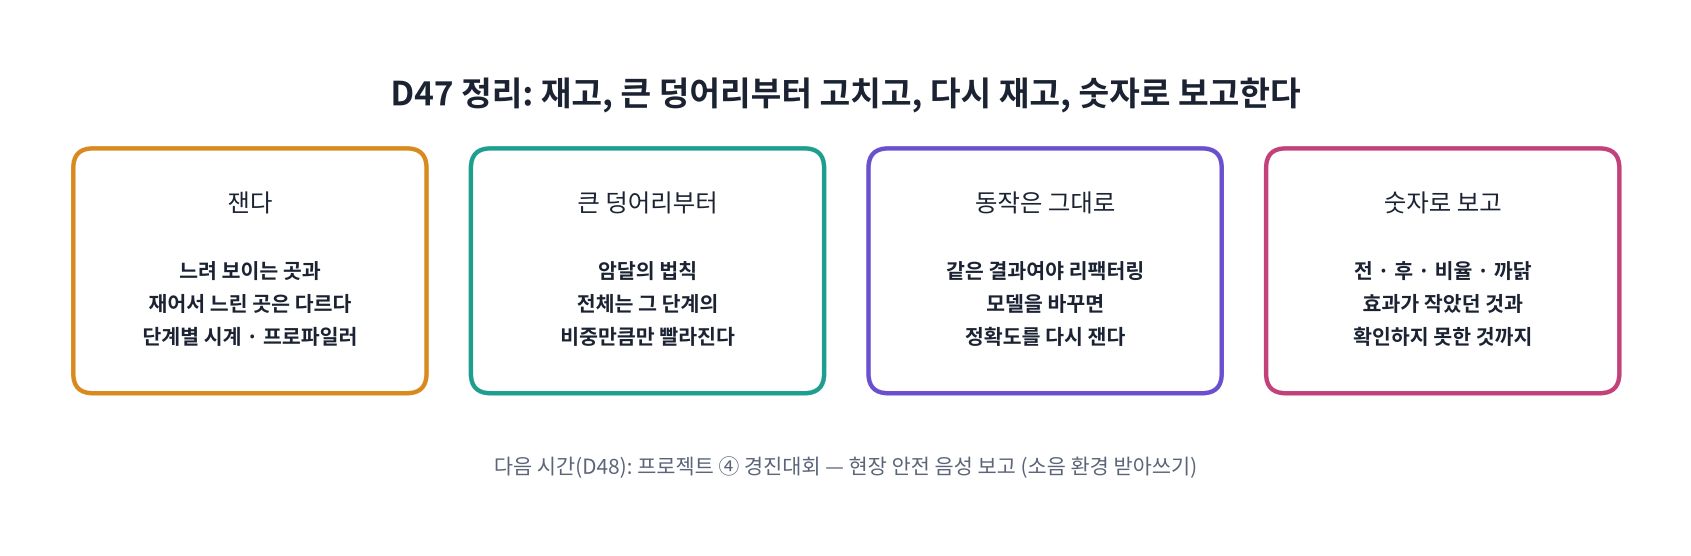

| 오늘 한 일 | 배운 것 |
|---|---|
| 레거시를 돌려 보고 잼 | 느려 보이는 곳과 재어서 느린 곳은 다르다. 고치기 전에 잰다 |
| 암달의 법칙 | 한 단계를 아무리 빠르게 해도 전체는 그 단계의 비중만큼만 빨라진다. 큰 덩어리부터 |
| K1 ~ K3 | 비싼 준비는 한 번만 · 작은 모델로 · 한꺼번에. 정확도는 다시 잰다 |
| K4 ~ K6 | 안 해도 되는 일을 하지 않는다. 시간의 병목과 비용의 병목은 다른 곳에 있다 |
| 카드 검사 | 동작이 같아야 리팩터링이다. 빨라졌는데 답이 틀려지면 고장이다 |
| 전후 보고서 | 고치기 전의 값 · 고친 뒤의 값 · 비율 · 까닭 · 확인하지 못한 것 |

**오늘의 산출물**: `before_after_report.html` · `before_after.json` · 개선 카드 6장

### ✍️ 회고 (5분 · 아래에 직접 적어 보세요)

1. 코드를 읽고 짐작한 "가장 느린 곳"은 어디였고, 재어 보니 어디였나요?
2. 한 카드를 끼운 뒤 "가장 느린 단계"가 바뀐 적이 있나요? 무엇에서 무엇으로 바뀌었나요?
3. 내가 맡은 서비스나 과제 가운데 "재 보지 않고 고친" 것이 있다면 무엇인가요?

> ⚠️ **오늘 하지 않은 것**: 실제 LLM(오늘은 규칙으로 흉내 내어 시간은 재지 않고 토큰만 셈), 실제 토크나이저(한글 한 글자를 1토큰으로 센 근사), 1시간짜리 실제 회의 녹음(55초 녹음의 비율로 어림), 화자 구분, GPU와 faster-whisper(D8 · D42. 오늘은 CPU의 sherpa-onnx), 여러 요청이 동시에 올 때의 부하 시험(D42), 여러 번 재어 흔들림을 보는 일(도전 과제).

**내일(D48)은 경진대회입니다.** 공장과 건설 현장의 소음이 섞인 안전 보고 음성을 받아쓰고, 숨겨 둔 평가 세트의 점수로 순위를 매깁니다. 제출 횟수에 한도가 있습니다. 오늘 배운 "바꾸면 잰다"를 정확도에 씁니다.